In [ ]:
# Importamos Pandas con el alias pd para trabajar con datos en tablas
import pandas as pd

# Leemos el CSV del directorio de trabajo y guardamos sus datos en un DataFrame llamado consumo_df
consumo_df = pd.read_csv('dataset_consumo_electrico_30000.csv')

# Mostramos los cinco primeros registros para realizar una inspección inicial de las columnas y sus valores
display(consumo_df.head())

,id_registro,edad_vivienda_anios,superficie_m2,numero_personas,habitaciones,dias_facturacion,temperatura_media_c,temperatura_minima_c,temperatura_maxima_c,mes,...,tipo_agua_caliente,aire_acondicionado,paneles_solares,numero_electrodomesticos,teletrabajo,nivel_ocupacion_diurna,potencia_contratada_kw,tipo_tarifa,anio,consumo_mensual_kwh
0,1,86,175.2,2.0,5.0,31.0,10.3,5.3,21.9,3,...,Gas,No,No,7.0,No,Media,3.41,Fija,2026,601.7
1,2,18,146.6,3.0,5.0,31.0,8.2,-1.9,12.0,7,...,Gas,No,No,10.0,No,Alta,5.23,Fija,2021,731.6
2,3,2,103.8,4.0,2.0,30.0,19.8,7.2,25.0,12,...,Solar,Sí,No,8.0,Sí,Alta,4.54,Fija,2023,499.2
3,4,64,85.0,5.0,3.0,31.0,19.9,12.3,29.3,1,...,Gas,Sí,No,9.0,No,Alta,4.87,Fija,2023,721.2
4,5,36,74.8,2.0,1.0,30.0,9.7,1.8,13.8,5,...,Solar,No,No,4.0,No,Media,2.74,Fija,2023,314.8


In [ ]:
# Importamos la función que permite separar los datos en un conjunto de entrenamiento y otro de test
from sklearn.model_selection import train_test_split

# Seleccionamos las siete variables predictoras del conjunto ampliado
variables = [
    "superficie_m2",
    "numero_personas",
    "tipo_calefaccion",
    "aire_acondicionado",
    "nivel_aislamiento",
    "temperatura_media_c",
    "numero_electrodomesticos"
]

# Conservamos las siete predictoras y la variable objetivo
# Eliminamos las filas con algún valor ausente en estas columnas
datos = consumo_df[variables + ["consumo_mensual_kwh"]].dropna()

# Separamos las características de entrada (x) del consumo mensual real que queremos predecir
x = datos[variables].copy()
consumo_mensual_kwh = datos["consumo_mensual_kwh"].copy()

# Reservamos el 70% de registros para entrenar, el 30% restante evaluarán predicciones.
# La semilla 42 permite repetir la misma partición
train_x, test_x, train_y, test_y = train_test_split(
    x,
    consumo_mensual_kwh,
    test_size=0.30,
    random_state=42
)

# Convertimos las categorías de texto en columnas de ceros y unos. Las columnas numéricas originales se mantienen
train_x = pd.get_dummies(train_x, dtype=int)
test_x = pd.get_dummies(test_x, dtype=int)

# Alineamos las columnas de test con las de entrenamiento: mismos nombres, orden y cero en las columnas que falten
test_x = test_x.reindex(
    columns=train_x.columns,
    fill_value=0
)

# Mostramos cuántas viviendas se usan en cada conjunto y una muestra de los datos de entrenamiento ya preparados
print("Viviendas para entrenar:", len(train_x))
print("Viviendas para test:", len(test_x))

display(train_x.head())

Viviendas para entrenar: 20981
Viviendas para test: 8993


,superficie_m2,numero_personas,temperatura_media_c,numero_electrodomesticos,tipo_calefaccion_Biomasa,tipo_calefaccion_Bomba de calor,tipo_calefaccion_Eléctrica,tipo_calefaccion_Gas,tipo_calefaccion_Ninguna,aire_acondicionado_No,aire_acondicionado_Sí,nivel_aislamiento_Alto,nivel_aislamiento_Bajo,nivel_aislamiento_Medio
29802,128.5,3.0,21.2,9.0,0,1,0,0,0,0,1,0,1,0
12932,154.6,5.0,15.3,10.0,0,0,0,0,1,1,0,0,0,1
27090,53.8,4.0,18.8,9.0,0,0,0,1,0,1,0,0,1,0
27642,108.1,3.0,21.5,9.0,0,0,0,0,1,0,1,1,0,0
24006,179.6,2.0,8.4,8.0,0,0,0,0,1,0,1,0,0,1


In [ ]:
# Regresión lineal: predice mediante una combinación lineal de las variables.
from sklearn.linear_model import LinearRegression

# Árbol de decisión: predice aplicando reglas que dividen los datos.
from sklearn.tree import DecisionTreeRegressor

# Random Forest: combina varios árboles y promedia sus predicciones.
from sklearn.ensemble import RandomForestRegressor

# Gradient Boosting: añade árboles sucesivamente para corregir errores.
from sklearn.ensemble import GradientBoostingRegressor

# Guardamos los modelos en un diccionario para identificarlos por su nombre.
# Fijamos la semilla en los modelos que incorporan aleatoriedad.
modelos = {
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# Entrenamos cada modelo con los mismos datos:
# train_x contiene los predictores preparados.
# train_y contiene el consumo mensual real de esas viviendas.

modelos["Regresión lineal"].fit(train_x, train_y)
print("Regresión lineal entrenada.")

modelos["Árbol de decisión"].fit(train_x, train_y)
print("Árbol de decisión entrenado.")

modelos["Random Forest"].fit(train_x, train_y)
print("Random Forest entrenado.")

modelos["Gradient Boosting"].fit(train_x, train_y)
print("Gradient Boosting entrenado.")

Regresión lineal entrenada.
Árbol de decisión entrenado.
Random Forest entrenado.
Gradient Boosting entrenado.


In [ ]:
# Importamos la función que calcula el error absoluto medio.
from sklearn.metrics import mean_absolute_error

# Lista para guardar el MAE de cada modelo.
resultados = []

# Diccionario para conservar las predicciones de cada modelo.
predicciones_modelos = {}

# Recorremos los cuatro modelos ya entrenados.
for nombre, modelo in modelos.items():

    # Predecimos el consumo de las viviendas reservadas para test.
    predicciones = modelo.predict(test_x)

    # Guardamos las predicciones para mostrarlas después.
    predicciones_modelos[nombre] = predicciones

    # Calculamos la media de las diferencias absolutas
    # entre los consumos reales y los predichos.
    mae = mean_absolute_error(test_y, predicciones)

    # Guardamos el nombre del modelo y su error en kWh.
    resultados.append({
        "Modelo": nombre,
        "MAE (kWh)": mae
    })

# Convertimos los resultados en una tabla de Pandas.
tabla_resultados = pd.DataFrame(resultados)

# Ordenamos de menor a mayor MAE y reiniciamos el índice.
tabla_resultados = tabla_resultados.sort_values(
    "MAE (kWh)"
).reset_index(drop=True)

# Mostramos los resultados redondeados a dos decimales.
display(tabla_resultados.round(2))

,Modelo,MAE (kWh)
0,Gradient Boosting,75.46
1,Regresión lineal,75.47
2,Random Forest,79.50
3,Árbol de decisión,108.78


In [ ]:
# Crear la tabla con los consumos reales
tabla_predicciones = pd.DataFrame({
    "Consumo real (kWh)": test_y
})

# Añadir las predicciones de cada modelo
for nombre, predicciones in predicciones_modelos.items():
    tabla_predicciones[nombre] = predicciones

# Mostrar diez viviendas de test
display(tabla_predicciones.head(10).round(2))

,Consumo real (kWh),Regresión lineal,Árbol de decisión,Random Forest,Gradient Boosting
22549,725.0,773.93,861.1,784.07,795.83
24435,708.2,622.89,650.9,576.05,610.41
19769,558.9,483.28,519.8,500.16,486.88
13561,430.8,448.55,370.2,486.18,464.06
15525,600.8,610.89,771.3,601.06,608.64
29944,731.5,655.78,721.2,613.58,622.93
1536,607.6,647.61,701.2,631.38,619.37
21394,701.9,630.82,782.8,604.38,621.35
24010,665.6,564.80,397.8,527.12,568.57
25572,576.3,625.62,531.9,583.16,614.62


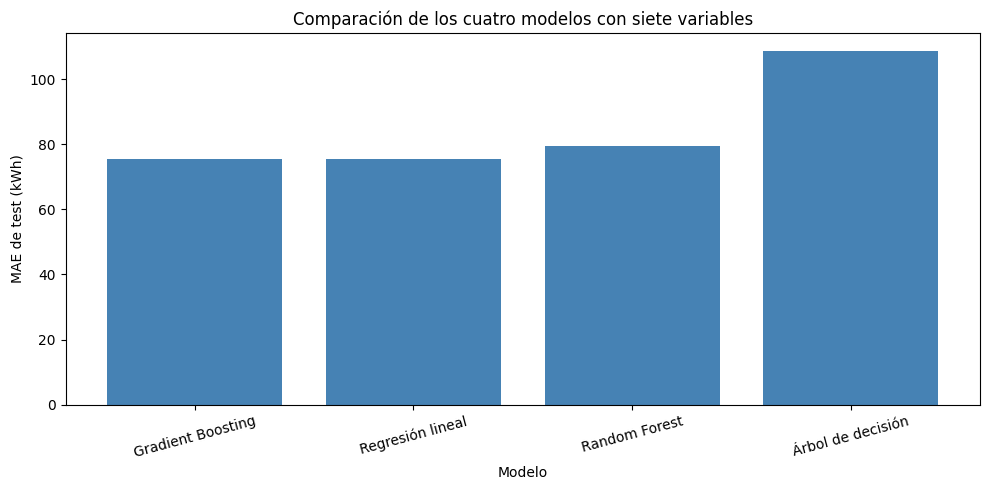

In [ ]:
# Importamos Matplotlib para crear gráficos.
import matplotlib.pyplot as plt

# Definimos el tamaño de la figura.
plt.figure(figsize=(10, 5))

# Representamos el MAE de cada modelo mediante barras.
plt.bar(
    tabla_resultados["Modelo"],
    tabla_resultados["MAE (kWh)"],
    color="steelblue"
)

# Añadimos el título y las etiquetas de los ejes.
plt.title("Comparación de los cuatro modelos con siete variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
# Inclinamos los nombres para facilitar su lectura.
plt.xticks(rotation=15)
# Ajustamos los márgenes para evitar recortes.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()

In [ ]:
# Seleccionamos el primer modelo de la tabla, ordenada por MAE ascendente.
mejor_modelo = tabla_resultados.iloc[0]["Modelo"]
# Guardamos el menor MAE observado con siete variables.
menor_mae = tabla_resultados.iloc[0]["MAE (kWh)"]

# Mostramos el modelo y su MAE con dos decimales.
print("Modelo con menor MAE:", mejor_modelo)
print(f"Error absoluto medio: {menor_mae:.2f} kWh")

Modelo con menor MAE: Gradient Boosting
Error absoluto medio: 75.46 kWh


In [ ]:
# Importamos clone para crear modelos sin entrenar con los mismos parámetros.
from sklearn.base import clone

# Seleccionar las columnas correspondientes a las cuatro variables.
# Las categóricas ya están convertidas mediante get_dummies().
columnas_reducidas = [
    columna
    for columna in train_x.columns
    if columna in ["superficie_m2", "numero_personas"]
    or columna.startswith("tipo_calefaccion_")
    or columna.startswith("aire_acondicionado_")
]

# Mantener las mismas viviendas de entrenamiento y test
train_x_reducido = train_x[columnas_reducidas].copy()
test_x_reducido = test_x[columnas_reducidas].copy()

# Mostramos las dimensiones del experimento reducido.
print("Variables originales del conjunto reducido: 4")
print("Columnas después de codificar:", len(columnas_reducidas))
print("Viviendas para entrenar:", len(train_x_reducido))
print("Viviendas para test:", len(test_x_reducido))

# Crear modelos nuevos con los mismos parámetros.
# No se modifican los modelos entrenados con siete variables.
modelos_reducidos = {
    nombre: clone(modelo)
    for nombre, modelo in modelos.items()
}

# Preparamos los contenedores de errores y predicciones.
resultados_reducidos = []
predicciones_reducidas = {}

# Recorremos los cuatro modelos nuevos.
for nombre, modelo in modelos_reducidos.items():

    # Entrenar con las cuatro variables
    modelo.fit(train_x_reducido, train_y)

    # Predecir sobre las mismas viviendas de test
    predicciones = modelo.predict(test_x_reducido)

    # Guardar las predicciones
    predicciones_reducidas[nombre] = predicciones

    # Calcular el MAE
    mae = mean_absolute_error(test_y, predicciones)

    # Guardamos el nombre y el MAE de cada modelo.
    resultados_reducidos.append({
        "Modelo": nombre,
        "MAE (kWh)": mae
    })

# Convertimos los resultados en una tabla.
tabla_resultados_reducidos = pd.DataFrame(resultados_reducidos)

# Ordenamos los modelos de menor a mayor MAE.
tabla_resultados_reducidos = (
    tabla_resultados_reducidos
    .sort_values("MAE (kWh)")
    .reset_index(drop=True)
)

# Mostramos la tabla con dos decimales.
print("\nResultados con cuatro variables:")
display(tabla_resultados_reducidos.round(2))

Variables originales del conjunto reducido: 4
Columnas después de codificar: 9
Viviendas para entrenar: 20981
Viviendas para test: 8993

Resultados con cuatro variables:


,Modelo,MAE (kWh)
0,Regresión lineal,82.84
1,Gradient Boosting,83.05
2,Random Forest,95.40
3,Árbol de decisión,117.57


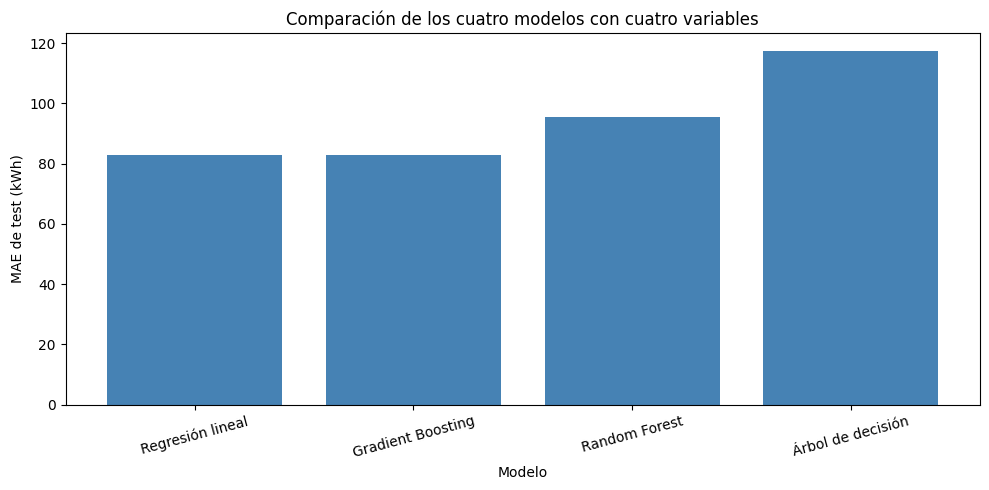

In [ ]:
# Importamos Matplotlib para representar los resultados.
import matplotlib.pyplot as plt

# Ordenar los modelos de menor a mayor MAE
datos_grafico = tabla_resultados_reducidos.sort_values("MAE (kWh)")

# Definimos el tamaño de la figura.
plt.figure(figsize=(10, 5))

# Representamos el MAE de los modelos con cuatro variables.
plt.bar(
    datos_grafico["Modelo"],
    datos_grafico["MAE (kWh)"],
    color="steelblue"
)

# Añadimos el título y las etiquetas de los ejes.
plt.title("Comparación de los cuatro modelos con cuatro variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
# Inclinamos los nombres para facilitar su lectura.
plt.xticks(rotation=15)
# Ajustamos los márgenes del gráfico.
plt.tight_layout()

# Mostramos el gráfico.
plt.show()

In [ ]:
# Preparar la tabla de cuatro variables
tabla_4 = tabla_resultados_reducidos.rename(
    columns={"MAE (kWh)": "MAE con 4 variables (kWh)"}
)

# Preparar la tabla de siete variables
tabla_7 = tabla_resultados.rename(
    columns={"MAE (kWh)": "MAE con 7 variables (kWh)"}
)

# Unir por nombre de modelo
tabla_comparacion = pd.merge(
    tabla_4,
    tabla_7,
    on="Modelo",
    validate="one_to_one"
)

# Diferencia positiva: siete variables reducen el error.
# Diferencia negativa: siete variables aumentan el error.
tabla_comparacion["Reducción del MAE (kWh)"] = (
    tabla_comparacion["MAE con 4 variables (kWh)"]
    - tabla_comparacion["MAE con 7 variables (kWh)"]
)

# Evitar divisiones por cero al calcular el porcentaje
mae_4 = tabla_comparacion["MAE con 4 variables (kWh)"]

# Calculamos la mejora porcentual respecto al MAE con cuatro variables.
tabla_comparacion["Mejora del MAE (%)"] = (
    tabla_comparacion["Reducción del MAE (kWh)"]
    / mae_4.where(mae_4 != 0)
    * 100
)

# Ordenamos por el MAE con siete variables y reiniciamos el índice.
tabla_comparacion = tabla_comparacion.sort_values(
    "MAE con 7 variables (kWh)"
).reset_index(drop=True)

# Mostramos los resultados con dos decimales.
display(tabla_comparacion.round(2))

,Modelo,MAE con 4 variables (kWh),MAE con 7 variables (kWh),Reducción del MAE (kWh),Mejora del MAE (%)
0,Gradient Boosting,83.05,75.46,7.59,9.13
1,Regresión lineal,82.84,75.47,7.37,8.89
2,Random Forest,95.40,79.50,15.90,16.67
3,Árbol de decisión,117.57,108.78,8.79,7.47


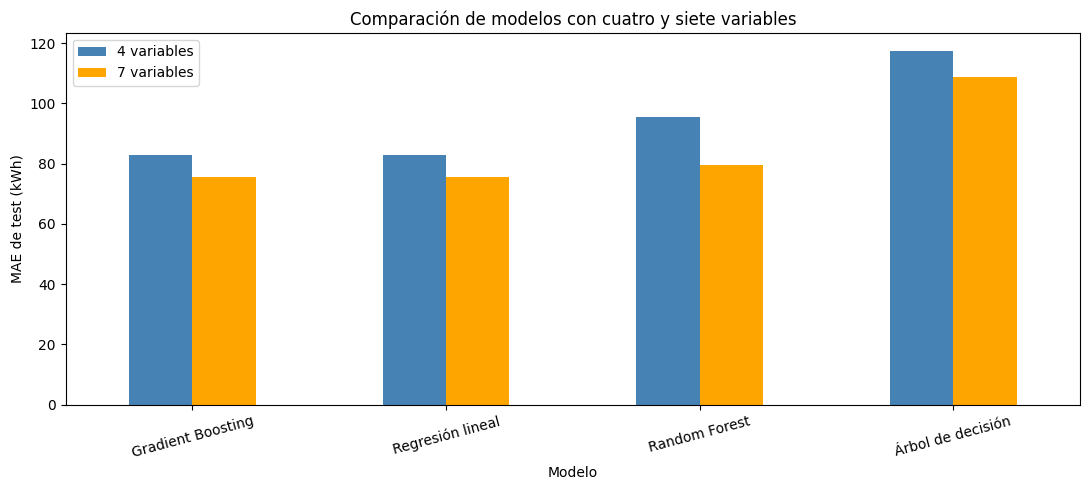

Resultados de las ocho combinaciones:


,Modelo,Conjunto,MAE (kWh)
0,Gradient Boosting,7 variables,75.46
1,Regresión lineal,7 variables,75.47
2,Random Forest,7 variables,79.50
3,Regresión lineal,4 variables,82.84
4,Gradient Boosting,4 variables,83.05
5,Random Forest,4 variables,95.40
6,Árbol de decisión,7 variables,108.78
7,Árbol de decisión,4 variables,117.57


Combinación con menor MAE observado:
Modelo: Gradient Boosting
Conjunto: 7 variables
MAE: 75.46 kWh


In [ ]:
# Gráfico de los cuatro algoritmos con ambos conjuntos
tabla_comparacion.set_index("Modelo")[
    [
        "MAE con 4 variables (kWh)",
        "MAE con 7 variables (kWh)"
    ]
].plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "orange"]
)

# Añadimos el título y las etiquetas de los ejes.
plt.title("Comparación de modelos con cuatro y siete variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
# Inclinamos los nombres y añadimos la leyenda de los conjuntos.
plt.xticks(rotation=15)
plt.legend(["4 variables", "7 variables"])
# Ajustamos los márgenes y mostramos el gráfico.
plt.tight_layout()
plt.show()

# Tabla con las ocho combinaciones
tabla_global = pd.concat(
    [
        tabla_resultados_reducidos.assign(Conjunto="4 variables"),
        tabla_resultados.assign(Conjunto="7 variables")
    ],
    ignore_index=True
)

# Seleccionamos las columnas y ordenamos las ocho combinaciones por MAE.
tabla_global = (
    tabla_global[["Modelo", "Conjunto", "MAE (kWh)"]]
    .sort_values("MAE (kWh)")
    .reset_index(drop=True)
)

# Mostramos la clasificación global con dos decimales.
print("Resultados de las ocho combinaciones:")
display(tabla_global.round(2))

# Mejor combinación según el MAE de esta evaluación
mejor_combinacion = tabla_global.iloc[0]

# Mostramos el modelo, el conjunto y el menor MAE observado.
print("Combinación con menor MAE observado:")
print("Modelo:", mejor_combinacion["Modelo"])
print("Conjunto:", mejor_combinacion["Conjunto"])
print(f"MAE: {mejor_combinacion['MAE (kWh)']:.2f} kWh")

# Guardar las tablas para utilizarlas en la memoria
tabla_comparacion.to_csv(
    "comparacion_4_y_7_variables.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardamos también la clasificación global, sin incluir el índice.
tabla_global.to_csv(
    "resultados_8_combinaciones.csv",
    index=False,
    encoding="utf-8-sig"
)